In [1]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
plt.style.use('fivethirtyeight')

## How can we predict the outcome of a new individual?

In [2]:
families = Table.read_table('family_heights.csv')
families

family,father,mother,child,children,order,sex
1,78.5,67,73.2,4,1,male
1,78.5,67,69.2,4,2,female
1,78.5,67,69,4,3,female
1,78.5,67,69,4,4,female
2,75.5,66.5,73.5,4,1,male
2,75.5,66.5,72.5,4,2,male
2,75.5,66.5,65.5,4,3,female
2,75.5,66.5,65.5,4,4,female
3,75,64,71,2,1,male
3,75,64,68,2,2,female


We will now average the heights of the parents and create a table with two columns
- Parent average height
- Child height

In [3]:
parent_avgs = (families.column('father') + families.column('mother'))/2

In [4]:
heights = Table().with_columns('Parent Average', parent_avgs,
                               'Child', families.column('child')
                              )
heights

Parent Average,Child
72.75,73.2
72.75,69.2
72.75,69
72.75,69
71,73.5
71,72.5
71,65.5
71,65.5
69.5,71
69.5,68


## Looking for association between two numerical variables

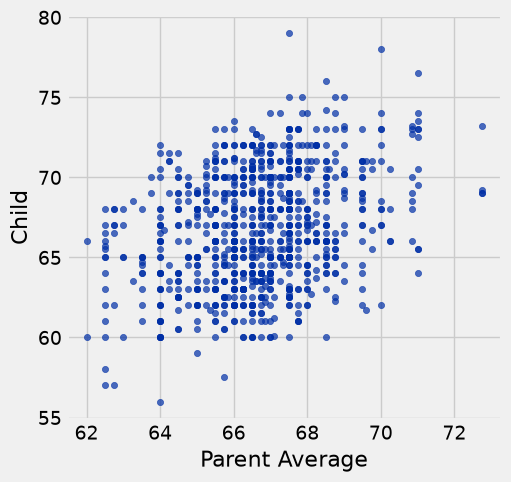

In [5]:
heights.scatter('Parent Average', 'Child')

### Predicting child's height for average parent height of 68

In [6]:
nearby = heights.where('Parent Average', are.between(67.5, 68.5))
nearby_mean = np.average(nearby.column('Child'))
nearby_mean

67.620000000000005

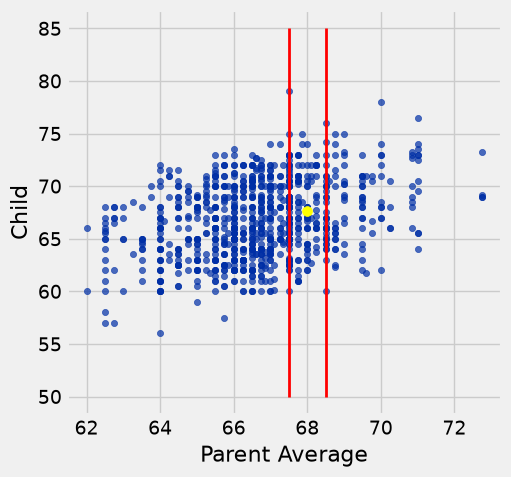

In [7]:
heights.scatter('Parent Average', 'Child')
plt.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plt.plot([68.5, 68.5], [50, 85], color='red', lw=2)
plt.scatter(68, nearby_mean, color='yellow', s=50);

In [8]:
def predict_child(h):
    nearby = heights.where('Parent Average', are.between(h - 0.5, h + 0.5))
    return np.average(nearby.column('Child'))

In [9]:
heights_with_predictions = heights.with_columns(
    'Prediction', heights.apply(predict_child, 'Parent Average'))

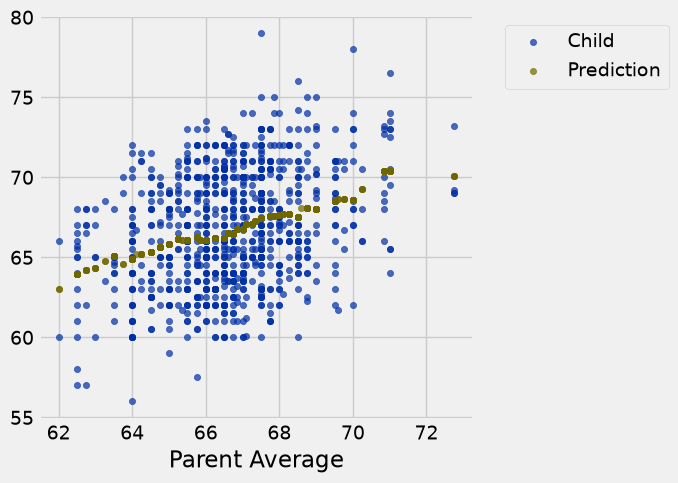

In [10]:
heights_with_predictions.scatter('Parent Average')

### More Associations

In [11]:
hybrid = Table.read_table('hybrid.csv')
hybrid.sample(6)

vehicle,year,msrp,acceleration,mpg,class
Freed/Freed Spike,2011,27972.1,6.29,50.81,Minivan
Panamera S,2013,96150,18.52,25,Large
Escalade 2WD,2013,74425,11.63,21,SUV
Insight,2012,18555.3,9.42,42,Compact
ActiveHybrid 7i,2011,102606,18.18,20,Midsize
Insight,2013,18600,11.76,42,Compact


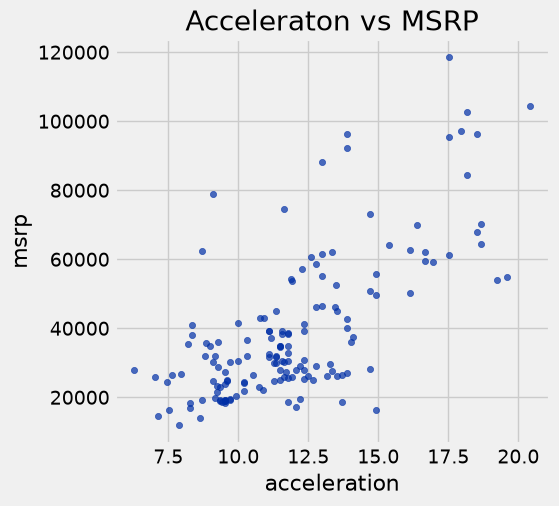

In [12]:
hybrid.scatter('acceleration', 'msrp')
plt.title('Acceleraton vs MSRP');

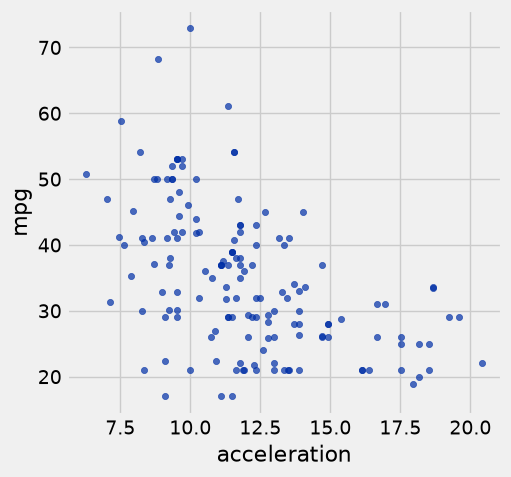

In [13]:
hybrid.scatter('acceleration', 'mpg')

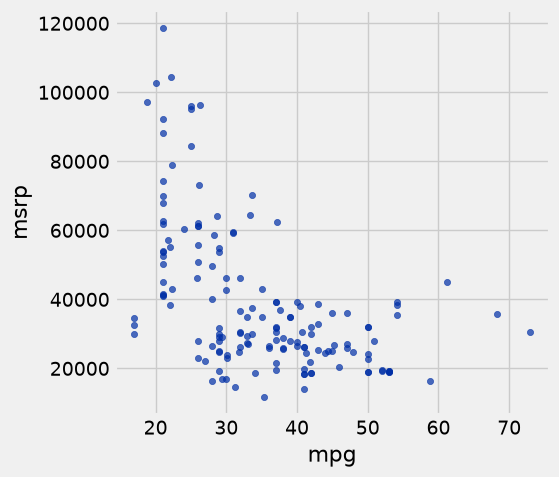

In [14]:
hybrid.scatter('mpg', 'msrp')

In [15]:
suv = hybrid.where('class', 'SUV')
suv.num_rows

39

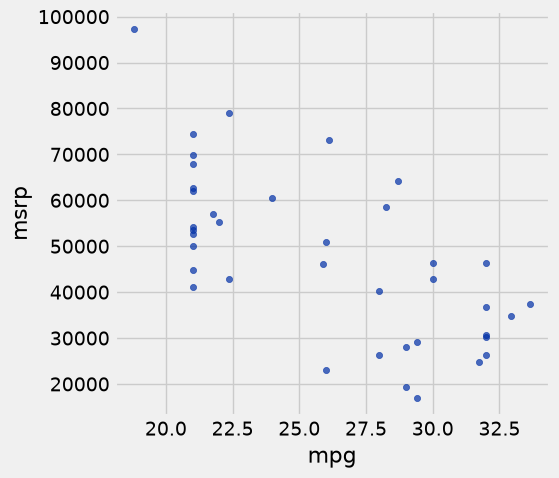

In [16]:
suv.scatter('mpg', 'msrp')

### Measure linear association using correlation coefficient ($r$)

In [17]:
def standard_units(x):
    '''Convert any array of numbers to standard units.'''
    return (x - np.average(x)) / np.std(x)

In [18]:
def correlation(t, x, y):
    '''t is a table; x and y are column labels'''
    x_in_std_units = standard_units(t.column(x))
    y_in_std_units = standard_units(t.column(y))
    return np.average(x_in_std_units * y_in_std_units)

In [19]:
correlation(hybrid, 'acceleration', 'msrp')

0.69557789969139783

In [20]:
correlation(suv, 'mpg', 'msrp')

-0.6667143635709919

### Always good to pair a calculation of $r$ with a visualization.

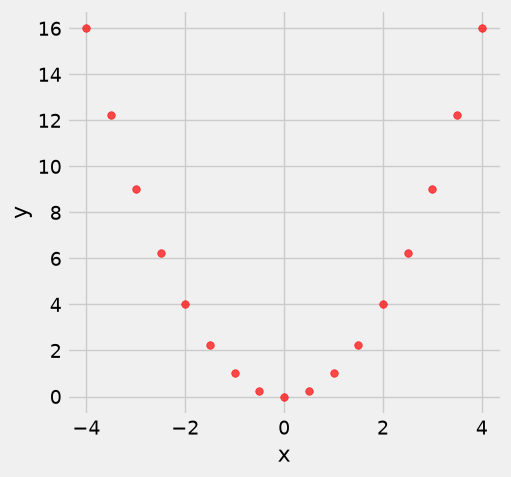

In [21]:
new_x = np.arange(-4, 4.1, 0.5)
nonlinear = Table().with_columns(
    'x', new_x,
    'y', new_x ** 2
)
nonlinear.scatter('x', 'y', s=30, color='red')

In [22]:
correlation(nonlinear, 'x', 'y')

0.0

### Outliers can greatly affect the value of $r$

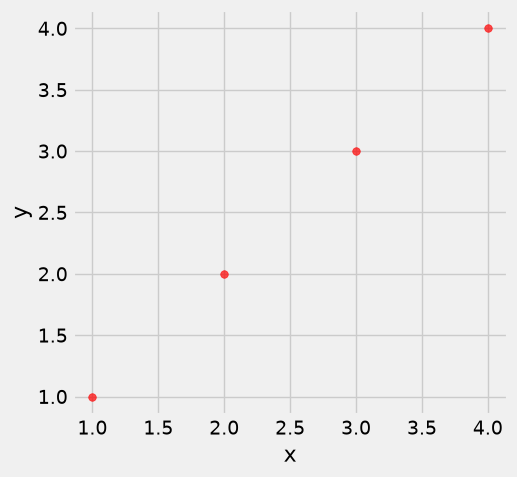

In [23]:
line = Table().with_columns(
    'x', make_array(1,2,3,4),
    'y', make_array(1,2,3,4)
)
line.scatter('x', 'y', s=30, color='red')

In [24]:
correlation(line, 'x', 'y')

1.0

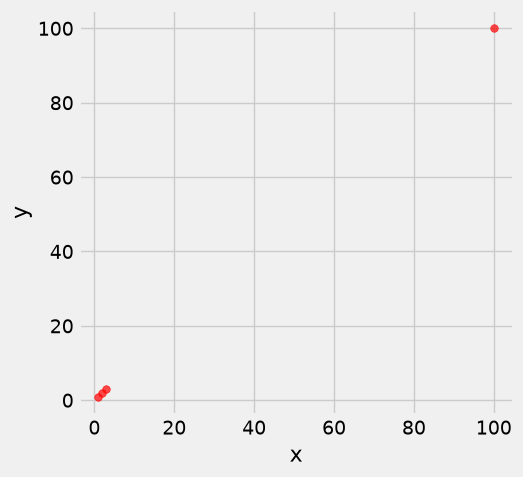

In [25]:
line = Table().with_columns(
    'x', make_array(1,2,3,100),
    'y', make_array(1,2,3,100)
)
line.scatter('x', 'y', s=30, color='red')

In [26]:
correlation(line, 'x', 'y')

1.0

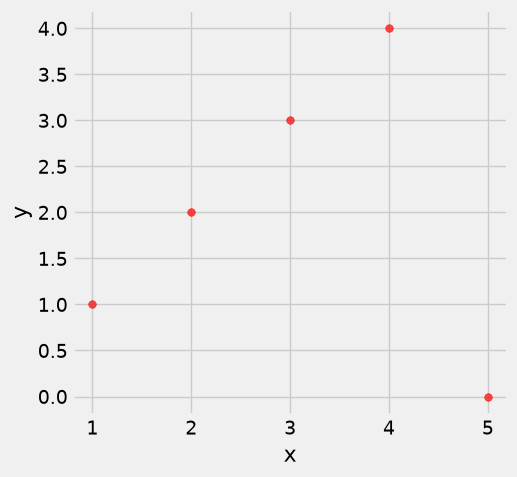

In [27]:
line = Table().with_columns(
    'x', make_array(1,2,3,4,5),
    'y', make_array(1,2,3,4,0)
)
line.scatter('x', 'y', s=30, color='red')

In [28]:
correlation(line, 'x', 'y')

0.0

### Correlations based on aggregated data can be misleading

In [29]:
sat2014 = Table.read_table('sat_scores.csv').sort('State')
sat2014

State,Participation Rate,Critical Reading,Math,Writing,Combined
Alabama,6.7,547,538,532,1617
Alaska,54.2,507,503,475,1485
Arizona,36.4,522,525,500,1547
Arkansas,4.2,573,571,554,1698
California,60.3,498,510,496,1504
Colorado,14.3,582,586,567,1735
Connecticut,88.4,507,510,508,1525
Delaware,100,456,459,444,1359
District of Columbia,100,440,438,431,1309
Florida,72.2,491,485,472,1448


In [30]:
correlation(sat2014, 'Critical Reading', 'Math')

0.98475584110674341

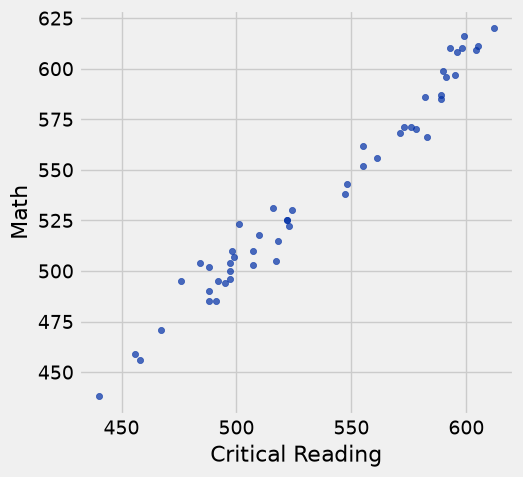

In [31]:
sat2014.scatter('Critical Reading', 'Math')

In [32]:
def rate_code(x):
    if x <= 25:
        return 'low'
    elif x <= 50:
        return 'low-moderate'
    elif x <= 75:
        return 'moderate-high'
    else:
        return 'high'

In [33]:
rate_codes = sat2014.apply(rate_code, 'Participation Rate')

In [34]:
sat2014 = sat2014.with_columns('Rate Code', rate_codes)
sat2014

State,Participation Rate,Critical Reading,Math,Writing,Combined,Rate Code
Alabama,6.7,547,538,532,1617,low
Alaska,54.2,507,503,475,1485,moderate-high
Arizona,36.4,522,525,500,1547,low-moderate
Arkansas,4.2,573,571,554,1698,low
California,60.3,498,510,496,1504,moderate-high
Colorado,14.3,582,586,567,1735,low
Connecticut,88.4,507,510,508,1525,high
Delaware,100,456,459,444,1359,high
District of Columbia,100,440,438,431,1309,high
Florida,72.2,491,485,472,1448,moderate-high


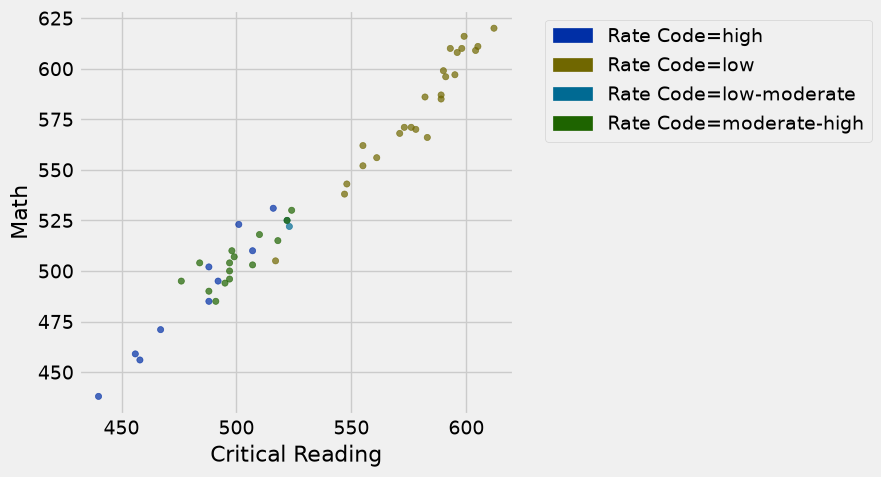

In [35]:
sat2014.scatter('Critical Reading', 'Math', group='Rate Code')

### Each individual point is a State, not a student!

In [54]:
def resize_window(lim=3.5):
    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)
def draw_line(slope=0, intercept=0, x=make_array(-4, 4), color='#1e90ff'):
    y = x*slope + intercept
    plt.plot(x, y, color=color, lw=3)
def draw_vertical_line(x_position, color='black'):
    x = make_array(x_position, x_position)
    y = make_array(-4, 4)
    plt.plot(x, y, color=color, lw=3)
def make_correlated_data(r):
    x = np.random.normal(0, 1, 1000)
    z = np.random.normal(0, 1, 1000)
    y = r*x + (np.sqrt(1-r**2))*z
    return x, y
 
def r_scatter(r):
    """Generate a scatter plot with a correlation approximately r"""
    plt.figure(figsize=(5,5))
    x, y = make_correlated_data(r)
    plt.scatter(x, y, color='darkblue', s=20)
    plt.xlim(-4, 4)
    plt.ylim(-4, 4)
def r_table(r):
    """
    Generate a table of 1000 data points with a correlation approximately r
    """
    np.random.seed(8)
    x, y = make_correlated_data(r)
    return Table().with_columns('x', x, 'y', y)

### Where is the prediction line?

$r$ = 0
The r_table function generates data that have: 
- A mean of 0 and a standard deviation of one (standard units)
- have a correlation given by the arguement supplied

In [68]:
example = r_table(0)
example

x,y
0.0912047,-1.12219
1.09128,-0.25849
-1.94697,0.314316
-1.38635,0.182474
-2.29649,0.880401
2.40983,1.49246
1.72784,0.356787
2.20456,2.91201
0.794828,-0.0611818
0.976421,1.52217


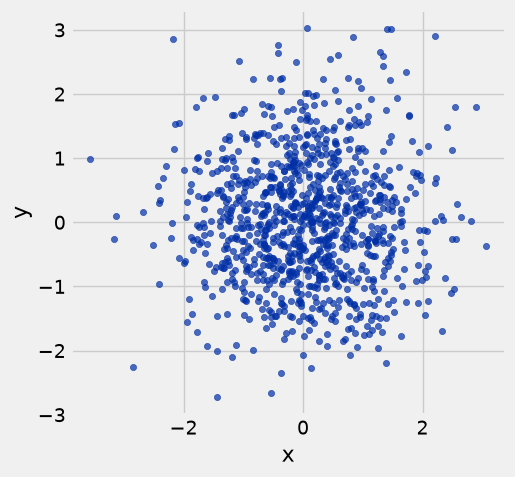

In [69]:
example.scatter('x')

In [72]:
def nn_prediction(x_val):
    neighbors = example.where('x', are.between(x_val - 0.5, x_val + 0.5))
    return np.average(neighbors.column('y'))

In [ ]:
example = example.with_columns('predicted y', example.apply(nn_prediction, 'x'))
example.scatter('x')
draw_line(slope = 0, color = 'red')

### $r$ = .99

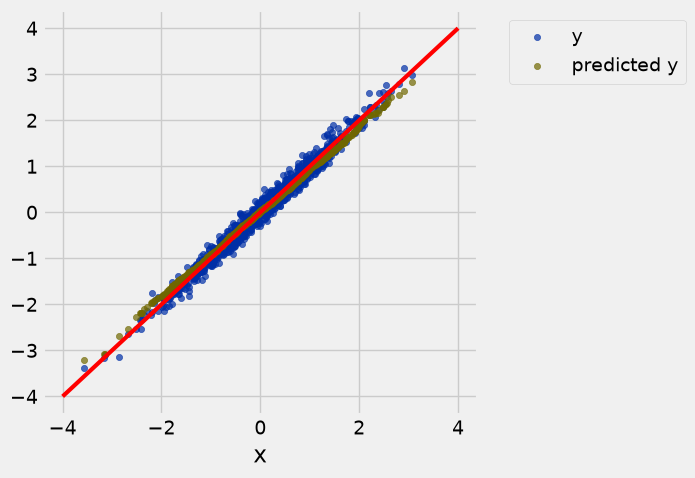

In [77]:
example = r_table(0.99)
example = example.with_columns('predicted y', example.apply(nn_prediction, 'x'))

example.scatter('x')
draw_line(slope = 1, color = 'red')

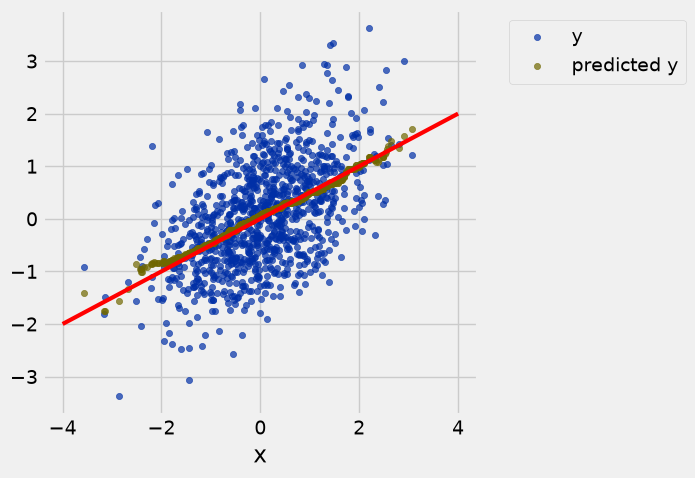

In [78]:
example = r_table(0.5)
example = example.with_columns('predicted y', example.apply(nn_prediction, 'x'))

example.scatter('x')
draw_line(slope = .5, color = 'red')

## Linear Regression: a statement about y and y pairs
- measured in standard units (su)

$$
frac{estimate of y = average of y}{SD of y} = r \bullet \frac{the given x - the average of x}{SD of x}
$$


slope of the regression line = $r \dot \frac{SD of y}{SD of x}$
intercept of the regression line $= the average of y = slope \bullet $


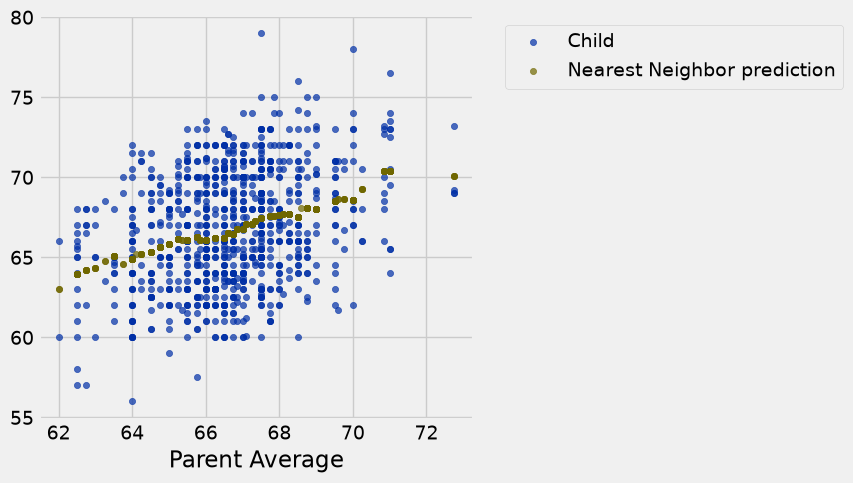

In [88]:
heights_with_prediction = heights.with_column(
    'Nearest Neighbor prediction', 
    heights.apply(predict_child, 'Parent Average'))
heights_with_prediction.scatter('Parent Average')

## Defining the linear regression in standard units

In [82]:
def slope(t, x, y):
    r = correlation(t, x, y)
    y_std = np.std(t.column(y))
    x_std = np.std(t.column(x))
    return r * y_std / x_std

In [83]:
def intercept(t, x, y):
    x_mean= np.mean(t.column(x))
    y_mean= np.mean(t.column(y))
    return y_mean - slope(t, x, y) * x_mean

In [93]:
predicted_heights_slope = slope(heights, 'Parent Average', 'Child')
predicted_heights_intercept = intercept(heights, 'Parent Average', 'Child')

heights_with_prediction = heights_with_prediction.with_column(
    'Regression Prediction',
    predicted_heights_slope * heights.column('Parent Average') + predicted_heights_intercept)

heights_with_prediction

Parent Average,Child,Nearest Neighbor prediction,Regression Prediction
72.75,73.2,70.1,70.8039
72.75,69.2,70.1,70.8039
72.75,69,70.1,70.8039
72.75,69,70.1,70.8039
71,73.5,70.4158,69.641
71,72.5,70.4158,69.641
71,65.5,70.4158,69.641
71,65.5,70.4158,69.641
69.5,71,68.5025,68.6443
69.5,68,68.5025,68.6443


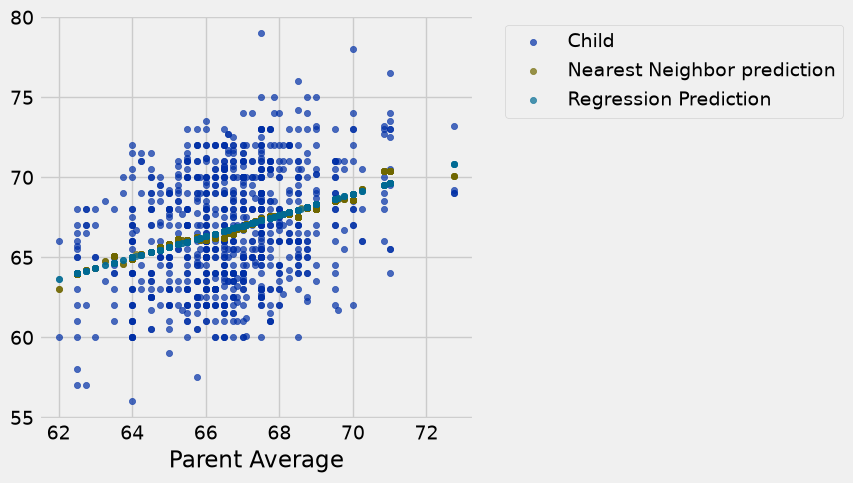

In [94]:
heights_with_prediction.scatter('Parent Average')

### Discission Question

In [95]:
# x variable: midterm scores
midterm_mean = 70
midterm_std = 10

# y variable: final scores
final_mean = 50
final_std = 12

# correlation 
r = .75

# new observation's x value
midterm_student = 90

In [97]:
midterm_student_su = (midterm_student - midterm_mean) / midterm_std
midterm_student_su

2.0

In [99]:
final_student_su = r * midterm_student_su
final_student_su

1.5

In [101]:
final_student = final_student_su * final_std + final_mean
final_student

68.0

In [104]:
slope_reg = r * final_std / midterm_std
final_student_reg = (slope_reg * midterm_student) + (final_mean - slope_reg * midterm_mean)
final_student_reg

68.0

### Quantifying errors in prediction (RMSE)

In [108]:
# use RMSE (Root Mean Square Error)
np.average((heights_with_prediction.column('Regression Prediction') - (heights_with_prediction.column('Child'))) ** 2) ** 0.5

3.3862655542854498